# EDA — Tahap 1: Sanity Check Data
**Dataset:** Indonesian Spices Dataset (31 kelas) — hasil split di `data_split/` (`prepare_data.ipynb`).

Tujuan tahap ini: memastikan data **layak dipakai** sebelum masuk ke preprocessing & training CNN.
Yang diperiksa:

1. Struktur folder & konsistensi dengan `manifest.csv`
2. Jumlah citra per kelas per split (cek ketimpangan kelas / class imbalance)
3. Integritas file (gambar corrupt / truncated / tidak bisa dibaca)
4. Properti citra (ukuran, aspect ratio, mode warna, ukuran file)
5. Duplikat (exact & near-duplicate) serta **kebocoran data** antar split
6. Inspeksi visual sampel tiap kelas
7. Statistik kanal RGB (mean/std) untuk normalisasi
8. Ringkasan temuan & implikasi ke tahap berikutnya

## 1. Setup & Load Manifest

In [1]:
from pathlib import Path
import hashlib
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
from tqdm.auto import tqdm

PROJECT_DIR = Path("/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject")
SPLIT_DIR = PROJECT_DIR / "data_split"
SPLITS = ("train", "val", "test")
IMG_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Jangan diam-diam menambal file rusak -> kita ingin tahu kalau ada yang truncated
ImageFile.LOAD_TRUNCATED_IMAGES = False
warnings.simplefilter("error", Image.DecompressionBombWarning)

pd.set_option("display.max_rows", 60)
plt.rcParams["figure.dpi"] = 110

manifest = pd.read_csv(SPLIT_DIR / "manifest.csv")
manifest["abspath"] = manifest["filepath"].map(lambda p: PROJECT_DIR / p)

print(f"Baris manifest : {len(manifest)}")
print(f"Jumlah kelas   : {manifest['label'].nunique()}")
print(f"Split          : {sorted(manifest['split'].unique())}")
manifest.head()

Baris manifest : 6031
Jumlah kelas   : 31
Split          : ['test', 'train', 'val']


/Users/akbarrzql/PycharmProjects/IndonesiaSpicesProject/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,split,label,filename,filepath,abspath
0,train,daun ketumbar,daun-ketumbar_28.jpg,data_split/train/daun ketumbar/daun-ketumbar_2...,/Users/akbarrzql/PycharmProjects/IndonesiaSpic...
1,train,serai,serai_164.jpg,data_split/train/serai/serai_164.jpg,/Users/akbarrzql/PycharmProjects/IndonesiaSpic...
2,train,kapulaga,kapulaga_32.JPG,data_split/train/kapulaga/kapulaga_32.JPG,/Users/akbarrzql/PycharmProjects/IndonesiaSpic...
3,train,bunga lawang,bunga-lawang_139.jpg,data_split/train/bunga lawang/bunga-lawang_139...,/Users/akbarrzql/PycharmProjects/IndonesiaSpic...
4,train,daun jeruk,daun-jeruk_171.jpg,data_split/train/daun jeruk/daun-jeruk_171.jpg,/Users/akbarrzql/PycharmProjects/IndonesiaSpic...


### 1.1 Konsistensi manifest vs isi disk
Manifest hanya berguna kalau benar-benar mencerminkan file di disk. Di sini dicek dua arah:
file yang tercatat tapi hilang, dan file di disk yang tidak tercatat.

In [2]:
disk_files = {
    p.relative_to(PROJECT_DIR).as_posix()
    for split in SPLITS
    for p in (SPLIT_DIR / split).rglob("*")
    if p.is_file() and p.suffix.lower() in IMG_EXTENSIONS
}
manifest_files = set(manifest["filepath"])

missing_on_disk = manifest_files - disk_files
untracked = disk_files - manifest_files

print(f"File di disk            : {len(disk_files)}")
print(f"File di manifest        : {len(manifest_files)}")
print(f"Tercatat tapi hilang    : {len(missing_on_disk)}")
print(f"Ada di disk, tak tercatat: {len(untracked)}")

# File non-gambar yang nyelip di folder split (mis. .DS_Store) -> harus 0 saat pakai ImageFolder
stray = [
    p.relative_to(PROJECT_DIR).as_posix()
    for split in SPLITS
    for p in (SPLIT_DIR / split).rglob("*")
    if p.is_file() and p.suffix.lower() not in IMG_EXTENSIONS
]
print(f"File non-gambar nyelip   : {len(stray)}")
for s in stray[:10]:
    print("  -", s)

assert not missing_on_disk, f"{len(missing_on_disk)} file hilang, jalankan ulang prepare_data.ipynb"

File di disk            : 6031
File di manifest        : 6031
Tercatat tapi hilang    : 0
Ada di disk, tak tercatat: 0


File non-gambar nyelip   : 0


## 2. Distribusi Kelas per Split

In [3]:
dist = (
    manifest.pivot_table(index="label", columns="split", values="filename", aggfunc="count")
    .reindex(columns=list(SPLITS))
    .fillna(0)
    .astype(int)
)
dist["total"] = dist.sum(axis=1)
dist_sorted = dist.sort_values("total", ascending=False)

print(dist_sorted.to_string())
print("\nTotal per split:")
print(dist[list(SPLITS)].sum())

n_total = int(dist["total"].sum())
mx, mn = int(dist["total"].max()), int(dist["total"].min())
print(f"\nTotal citra        : {n_total}")
print(f"Kelas terbanyak    : {dist['total'].idxmax()} ({mx})")
print(f"Kelas tersedikit   : {dist['total'].idxmin()} ({mn})")
print(f"Imbalance ratio    : {mx / mn:.2f}x")
print(f"Rata-rata per kelas: {dist['total'].mean():.1f} (std {dist['total'].std():.1f})")

# Syarat tugas: minimal 5 kelas & minimal 1000 citra
print(f"\nSyarat tugas >=5 kelas  : {len(dist)} -> {'OK' if len(dist) >= 5 else 'GAGAL'}")
print(f"Syarat tugas >=1000 citra: {n_total} -> {'OK' if n_total >= 1000 else 'GAGAL'}")

split          train  val  test  total
label                                 
kayu manis       146   32    31    209
bukan rempah     146   31    31    208
bawang bombai    146   31    31    208
kemiri           146   31    31    208
pala             144   31    31    206
daun kemangi     143   31    31    205
lada             143   31    31    205
wijen            143   31    31    205
bawang merah     143   31    31    205
saffron          143   30    31    204
bawang putih     143   31    30    204
kunyit           143   30    31    204
kemukus          143   31    30    204
vanili           141   30    31    202
kencur           141   31    30    202
kapulaga         141   30    31    202
lengkuas         138   30    29    197
jahe             137   30    29    196
adas             137   29    29    195
daun ketumbar    137   29    29    195
kluwek           136   29    29    194
serai            135   29    29    193
bunga lawang     134   29    29    192
daun salam       133   28

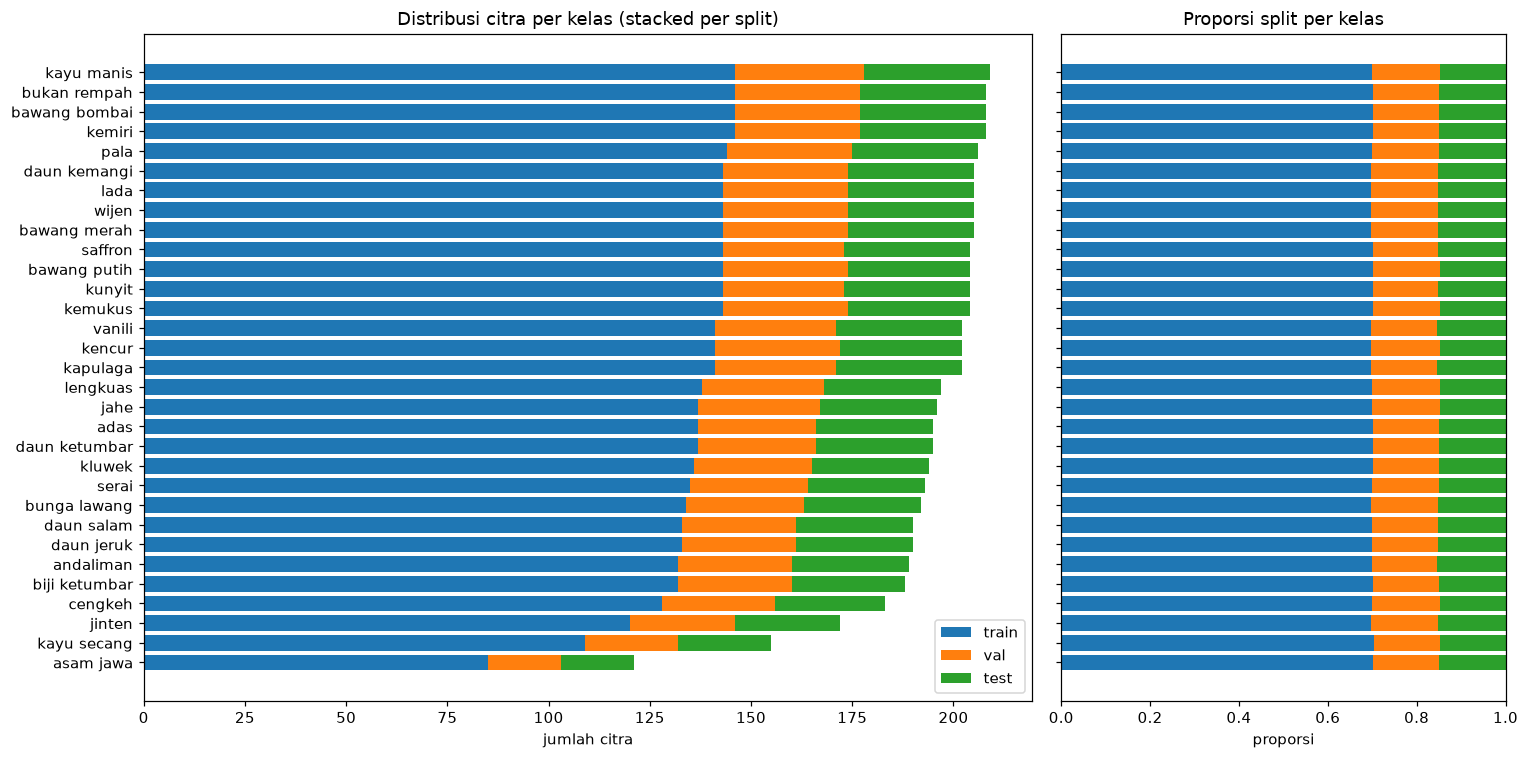

Deviasi proporsi train dari 0.70 (maks): 0.0032
Deviasi proporsi val   dari 0.15 (maks): 0.0035
Deviasi proporsi test  dari 0.15 (maks): 0.0035


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), gridspec_kw={"width_ratios": [2, 1]})

bottom = np.zeros(len(dist_sorted))
for split in SPLITS:
    axes[0].barh(dist_sorted.index, dist_sorted[split], left=bottom, label=split)
    bottom += dist_sorted[split].to_numpy()
axes[0].set_xlabel("jumlah citra")
axes[0].set_title("Distribusi citra per kelas (stacked per split)")
axes[0].invert_yaxis()
axes[0].legend()

# Proporsi split tiap kelas -> memastikan stratifikasi 70/15/15 benar-benar terjaga
prop = dist_sorted[list(SPLITS)].div(dist_sorted["total"], axis=0)
left = np.zeros(len(prop))
for split in SPLITS:
    axes[1].barh(prop.index, prop[split], left=left, label=split)
    left += prop[split].to_numpy()
axes[1].set_xlim(0, 1)
axes[1].set_yticklabels([])
axes[1].set_xlabel("proporsi")
axes[1].set_title("Proporsi split per kelas")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

print("Deviasi proporsi train dari 0.70 (maks):", f"{(prop['train'] - 0.70).abs().max():.4f}")
print("Deviasi proporsi val   dari 0.15 (maks):", f"{(prop['val'] - 0.15).abs().max():.4f}")
print("Deviasi proporsi test  dari 0.15 (maks):", f"{(prop['test'] - 0.15).abs().max():.4f}")

## 3. Integritas File & Properti Citra
Satu kali lintasan baca semua file: verifikasi header, decode penuh, lalu catat ukuran, mode warna,
ukuran file, dan hash untuk deteksi duplikat. Lintasan ini yang paling lama (~beberapa menit).

In [5]:
def dhash(img, size=8):
    """Perceptual hash sederhana (difference hash) untuk deteksi near-duplicate."""
    g = img.convert("L").resize((size + 1, size), Image.LANCZOS)
    a = np.asarray(g, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).flatten()
    return np.packbits(bits).tobytes().hex()


rows, broken, thumbs = [], [], {}

for r in tqdm(manifest.itertuples(index=False), total=len(manifest), desc="scan citra"):
    p = r.abspath
    try:
        raw = p.read_bytes()
        with Image.open(p) as im:
            im.verify()                 # cek struktur file
        with Image.open(p) as im:
            im.load()                   # decode penuh -> menangkap file truncated
            w, h = im.size
            mode, fmt = im.mode, im.format
            ph = dhash(im)
            thumbs[r.filepath] = np.asarray(
                im.convert("L").resize((32, 32), Image.BILINEAR), dtype=np.float32
            )
    except Exception as e:
        broken.append({"filepath": r.filepath, "split": r.split, "label": r.label,
                        "error": f"{type(e).__name__}: {e}"})
        continue

    rows.append({
        "split": r.split, "label": r.label, "filepath": r.filepath,
        "width": w, "height": h, "mode": mode, "format": fmt,
        "bytes": len(raw),
        "md5": hashlib.md5(raw).hexdigest(),
        "dhash": ph,
    })

meta = pd.DataFrame(rows)
broken_df = pd.DataFrame(broken)

print(f"\nBerhasil dibaca : {len(meta)}")
print(f"Gagal dibaca    : {len(broken_df)}")
if len(broken_df):
    display(broken_df)

scan citra:   0%|          | 0/6031 [00:00<?, ?it/s]

scan citra:   1%|          | 48/6031 [00:00<00:12, 465.84it/s]

scan citra:   2%|▏         | 95/6031 [00:00<00:21, 276.94it/s]

scan citra:   2%|▏         | 127/6031 [00:00<00:24, 236.99it/s]

scan citra:   3%|▎         | 153/6031 [00:00<00:25, 230.92it/s]

scan citra:   3%|▎         | 207/6031 [00:00<00:18, 313.89it/s]

... (132 outputs left out)

scan citra:  99%|█████████▊| 5952/6031 [00:17<00:00, 338.28it/s]

scan citra: 100%|█████████▉| 6010/6031 [00:17<00:00, 399.05it/s]

scan citra: 100%|██████████| 6031/6031 [00:17<00:00, 349.76it/s]


Berhasil dibaca : 6031
Gagal dibaca    : 0


In [6]:
meta["aspect"] = meta["width"] / meta["height"]
meta["megapixel"] = meta["width"] * meta["height"] / 1e6
meta["kb"] = meta["bytes"] / 1024

print("Statistik dimensi & ukuran file:")
print(meta[["width", "height", "aspect", "megapixel", "kb"]].describe().T.to_string())

print("\nMode warna:")
print(meta["mode"].value_counts())
print("\nFormat file:")
print(meta["format"].value_counts())

non_rgb = meta[meta["mode"] != "RGB"]
print(f"\nCitra non-RGB (grayscale/RGBA/palette): {len(non_rgb)}")
if len(non_rgb):
    print(non_rgb["label"].value_counts().head(10).to_string())

print("\nResolusi paling umum:")
print((meta["width"].astype(str) + "x" + meta["height"].astype(str)).value_counts().head(10).to_string())

TARGET = 224
too_small = meta[(meta["width"] < TARGET) | (meta["height"] < TARGET)]
print(f"\nCitra lebih kecil dari {TARGET}px pada salah satu sisi: {len(too_small)} ({len(too_small)/len(meta):.2%})")
print(f"Citra sangat kecil (<64px): {len(meta[(meta['width'] < 64) | (meta['height'] < 64)])}")
print(f"File mencurigakan kecil (<5 KB): {len(meta[meta['kb'] < 5])}")

Statistik dimensi & ukuran file:
            count        mean         std        min       25%        50%         75%          max
width      6031.0  621.155696  536.614281  59.000000  500.0000  500.00000  500.000000  6000.000000
height     6031.0  547.288012  443.732026  65.000000  400.0000  500.00000  500.000000  4080.000000
aspect     6031.0    1.147188    0.286401   0.173077    1.0000    1.00000    1.332223     3.406780
megapixel  6031.0    0.562760    1.675845   0.007912    0.2400    0.25000    0.250000    24.000000
kb         6031.0   67.273383  143.956586   2.728516   24.8125   40.37207   60.124023  5974.693359

Mode warna:
mode
RGB     6006
RGBA      19
P          6
Name: count, dtype: int64

Format file:
format
JPEG    5767
WEBP     214
PNG       50
Name: count, dtype: int64

Citra non-RGB (grayscale/RGBA/palette): 25
label
bawang bombai    8
daun kemangi     4
bawang putih     4
kapulaga         2
kemukus          2
asam jawa        2
andaliman        1
kencur           1
ka

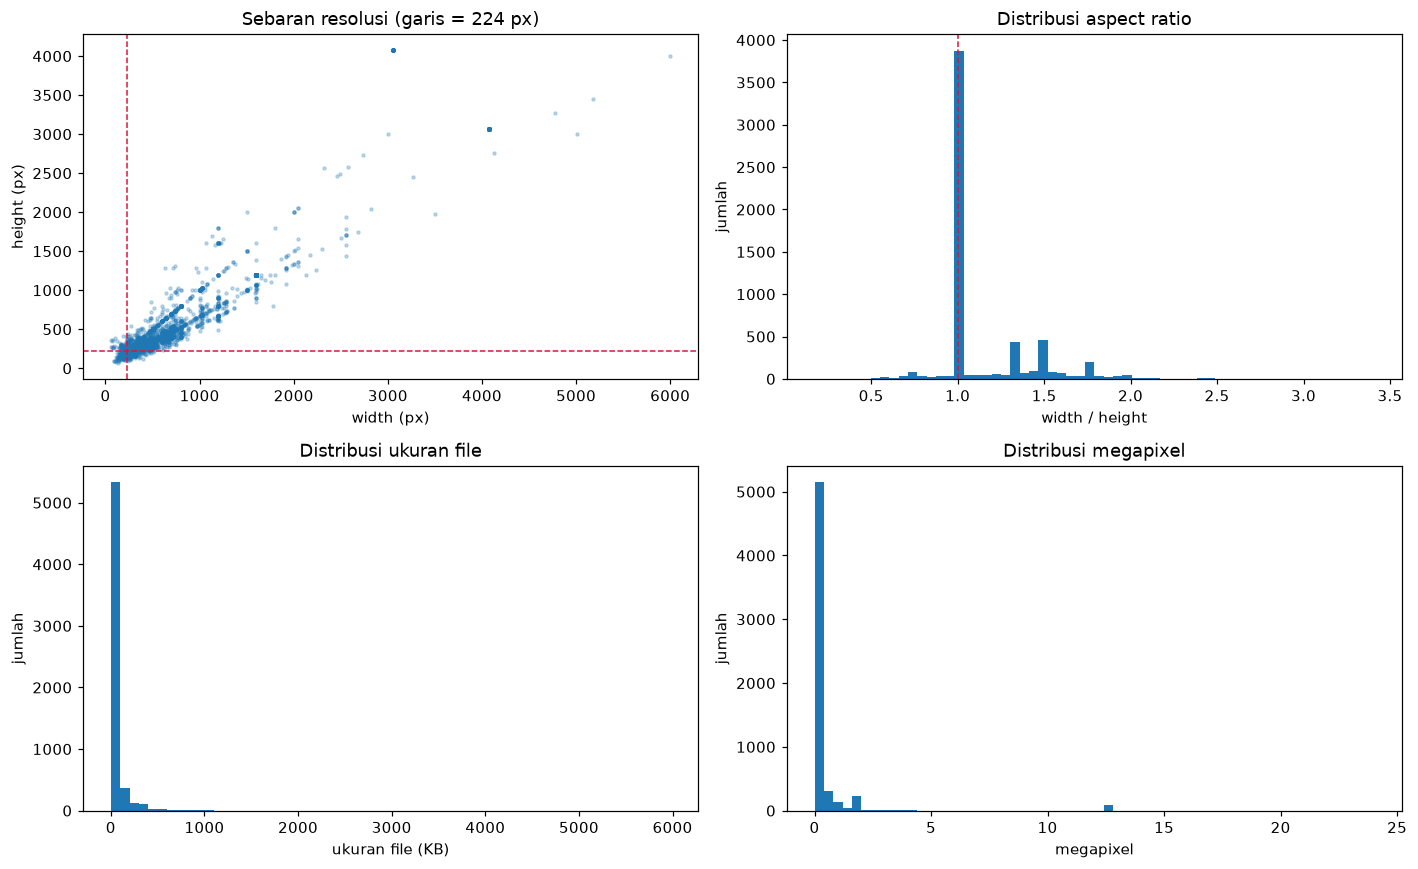

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

axes[0, 0].scatter(meta["width"], meta["height"], s=4, alpha=0.25)
axes[0, 0].axvline(TARGET, ls="--", lw=1, color="crimson")
axes[0, 0].axhline(TARGET, ls="--", lw=1, color="crimson")
axes[0, 0].set(xlabel="width (px)", ylabel="height (px)", title="Sebaran resolusi (garis = 224 px)")

axes[0, 1].hist(meta["aspect"], bins=60)
axes[0, 1].axvline(1.0, ls="--", lw=1, color="crimson")
axes[0, 1].set(xlabel="width / height", ylabel="jumlah", title="Distribusi aspect ratio")

axes[1, 0].hist(meta["kb"], bins=60)
axes[1, 0].set(xlabel="ukuran file (KB)", ylabel="jumlah", title="Distribusi ukuran file")

axes[1, 1].hist(meta["megapixel"], bins=60)
axes[1, 1].set(xlabel="megapixel", ylabel="jumlah", title="Distribusi megapixel")

plt.tight_layout()
plt.show()

## 4. Duplikat & Kebocoran Antar Split


In [8]:
RMSE_THRESHOLD = 5.0   # sama dengan ambang dedup di prepare_data.ipynb


def max_rmse(paths):
    t = [thumbs[p] for p in paths]
    return max(
        (float(np.sqrt(((t[i] - t[j]) ** 2).mean())) for i in range(len(t)) for j in range(i + 1, len(t))),
        default=0.0,
    )


def dup_report(meta, key):
    """Grup duplikat yang lolos verifikasi piksel, plus daftar false positive."""
    cand = meta[meta.duplicated(key, keep=False)]
    verified, false_pos = {}, []
    for k, g in cand.groupby(key):
        if max_rmse(list(g["filepath"])) < RMSE_THRESHOLD:
            verified[k] = g
        else:
            false_pos.append(k)

    n_files = sum(len(g) for g in verified.values())
    cross_split = [k for k, g in verified.items() if g["split"].nunique() > 1]
    cross_label = [k for k, g in verified.items() if g["label"].nunique() > 1]

    print(f"[{key}] kandidat grup (hash sama)        : {cand[key].nunique()}")
    print(f"[{key}] ditolak verifikasi piksel (FP)   : {len(false_pos)}")
    print(f"[{key}] grup duplikat terverifikasi      : {len(verified)} ({n_files} file)")
    print(f"[{key}] grup lintas split (LEAKAGE)      : {len(cross_split)}")
    print(f"[{key}] grup lintas label (label konflik): {len(cross_label)}")

    dup = pd.concat(verified.values()) if verified else cand.iloc[:0]
    return dup, verified, cross_split, cross_label


dup_md5, g_md5, leak_md5, conflict_md5 = dup_report(meta, "md5")
print()
dup_ph, g_ph, leak_ph, conflict_ph = dup_report(meta, "dhash")

[md5] kandidat grup (hash sama)        : 0
[md5] ditolak verifikasi piksel (FP)   : 0
[md5] grup duplikat terverifikasi      : 0 (0 file)
[md5] grup lintas split (LEAKAGE)      : 0
[md5] grup lintas label (label konflik): 0

[dhash] kandidat grup (hash sama)        : 9
[dhash] ditolak verifikasi piksel (FP)   : 9
[dhash] grup duplikat terverifikasi      : 0 (0 file)
[dhash] grup lintas split (LEAKAGE)      : 0
[dhash] grup lintas label (label konflik): 0


In [9]:
# Detail contoh kebocoran lintas split (paling berbahaya untuk validitas evaluasi)
leak_keys = leak_md5 or leak_ph
leak_key_col = "md5" if leak_md5 else "dhash"

if leak_keys:
    sample = (
        meta[meta[leak_key_col].isin(leak_keys[:10])]
        .sort_values([leak_key_col, "split"])[[leak_key_col, "split", "label", "filepath"]]
    )
    display(sample)
else:
    print("Tidak ada duplikat yang melintasi split. Evaluasi test set tidak terkontaminasi.")

if conflict_md5 or conflict_ph:
    ck = conflict_md5 or conflict_ph
    kcol = "md5" if conflict_md5 else "dhash"
    print(f"\nContoh gambar identik dengan label berbeda ({kcol}):")
    display(meta[meta[kcol].isin(ck[:10])].sort_values(kcol)[[kcol, "label", "split", "filepath"]])
else:
    print("\nTidak ada gambar identik dengan label berbeda.")

Tidak ada duplikat yang melintasi split. Evaluasi test set tidak terkontaminasi.

Tidak ada gambar identik dengan label berbeda.


In [10]:
# Visualisasi satu grup duplikat sebagai bukti (kalau ada)
groups_to_show = [k for k, g in g_md5.items() if len(g) > 1][:3]
if groups_to_show:
    for k in groups_to_show:
        g = g_md5[k]
        fig, axes = plt.subplots(1, len(g), figsize=(3 * len(g), 3.2))
        axes = np.atleast_1d(axes)
        for ax, row in zip(axes, g.itertuples(index=False)):
            ax.imshow(Image.open(PROJECT_DIR / row.filepath).convert("RGB"))
            ax.set_title(f"{row.split}/{row.label}\n{Path(row.filepath).name}", fontsize=8)
            ax.axis("off")
        plt.tight_layout()
        plt.show()
else:
    print("Tidak ada grup duplikat byte-identik untuk divisualisasikan.")

Tidak ada grup duplikat byte-identik untuk divisualisasikan.


## 5. Inspeksi Visual Sampel

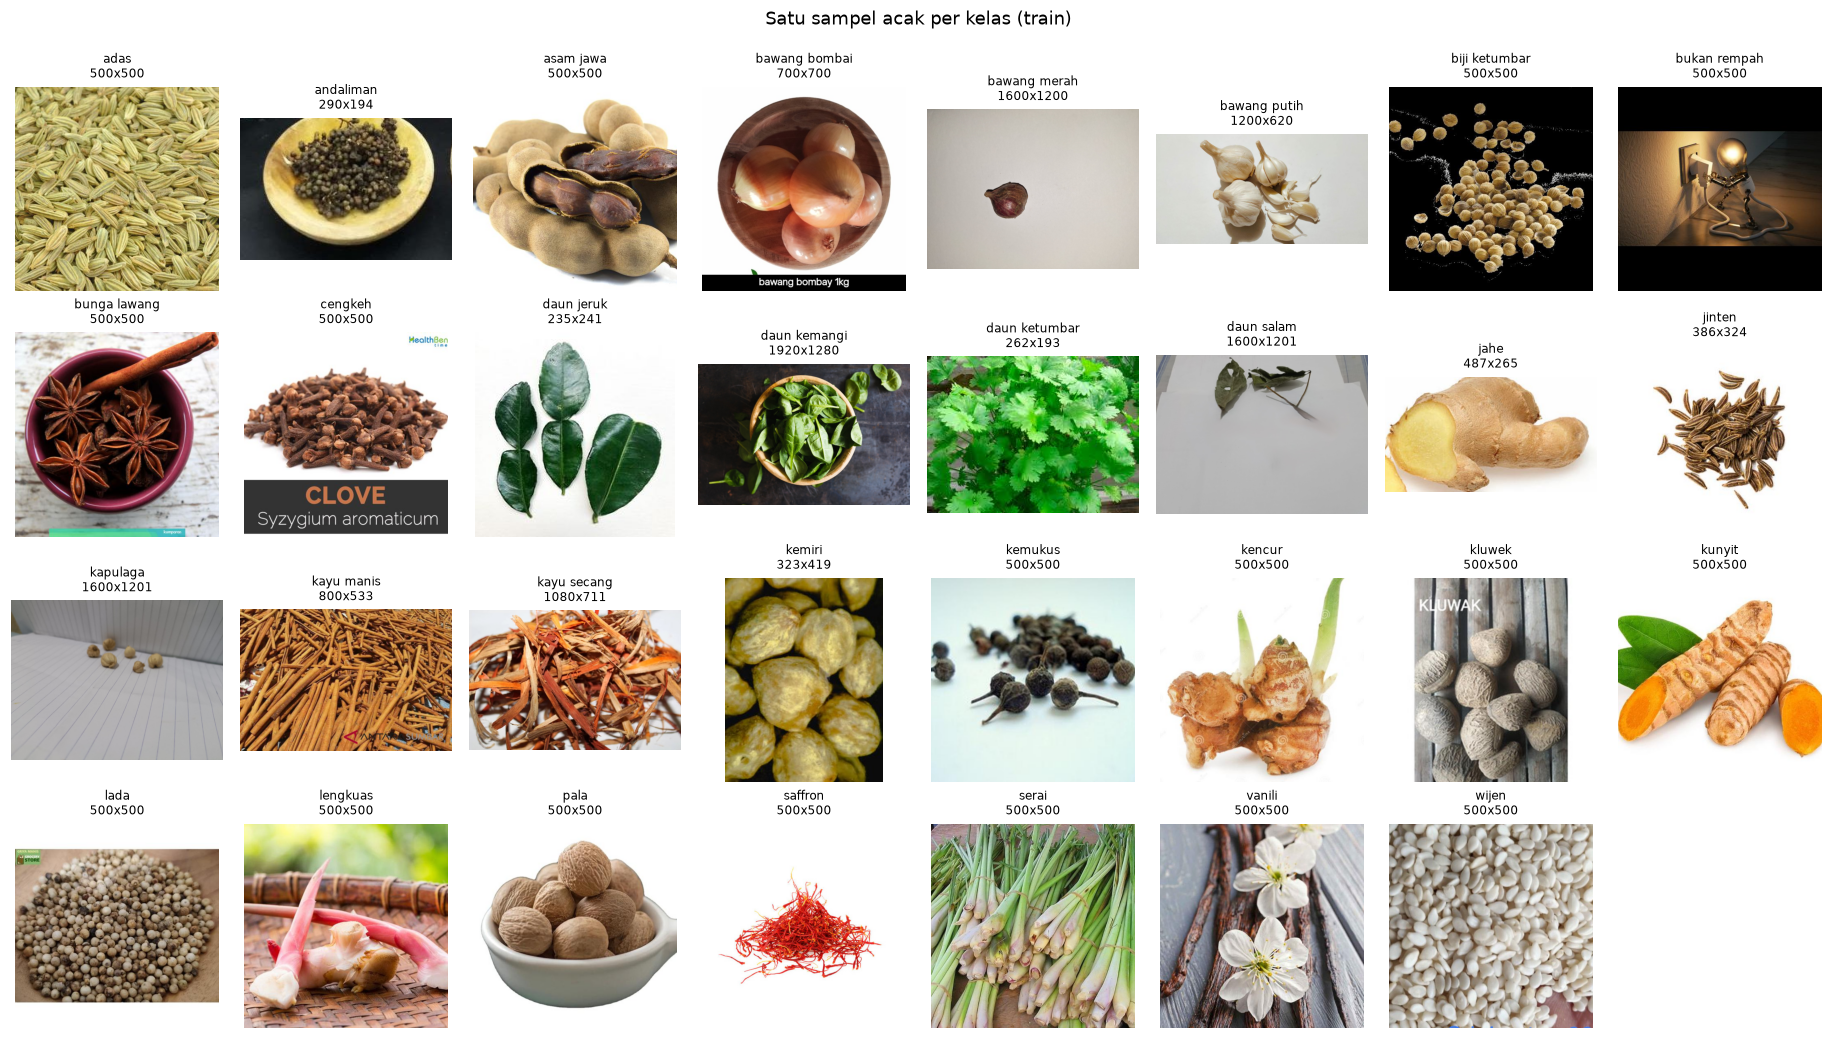

In [11]:
rng = np.random.default_rng(42)
labels = sorted(meta["label"].unique())

ncol = 8
nrow = int(np.ceil(len(labels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.1 * ncol, 2.35 * nrow))
for ax in axes.ravel():
    ax.axis("off")

for ax, label in zip(axes.ravel(), labels):
    pool = meta[(meta["label"] == label) & (meta["split"] == "train")]
    row = pool.iloc[rng.integers(len(pool))]
    ax.imshow(Image.open(PROJECT_DIR / row.filepath).convert("RGB"))
    ax.set_title(f"{label}\n{row.width}x{row.height}", fontsize=8)

fig.suptitle("Satu sampel acak per kelas (train)", y=1.0)
plt.tight_layout()
plt.show()

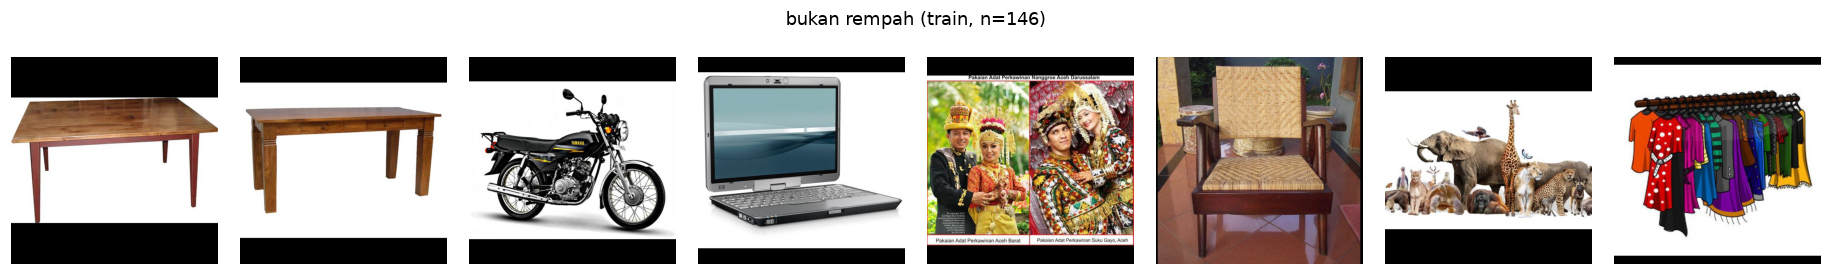

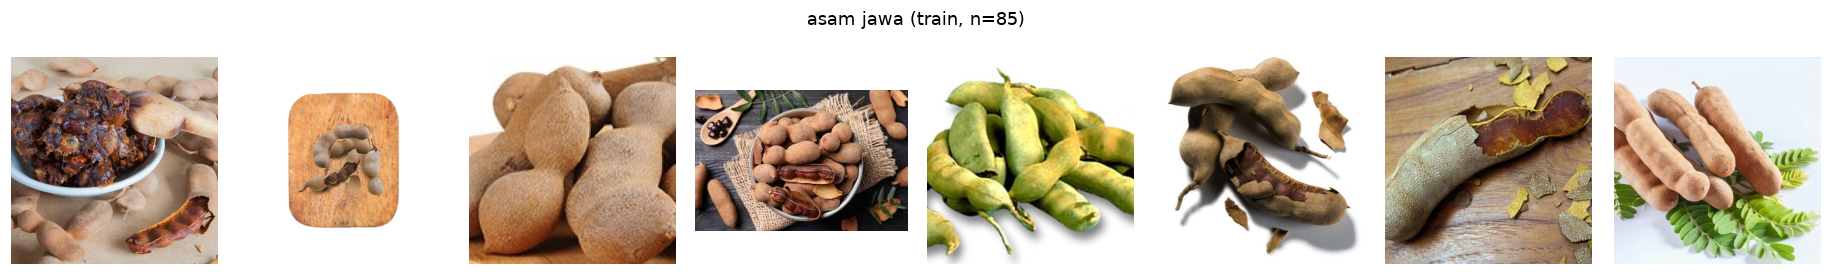

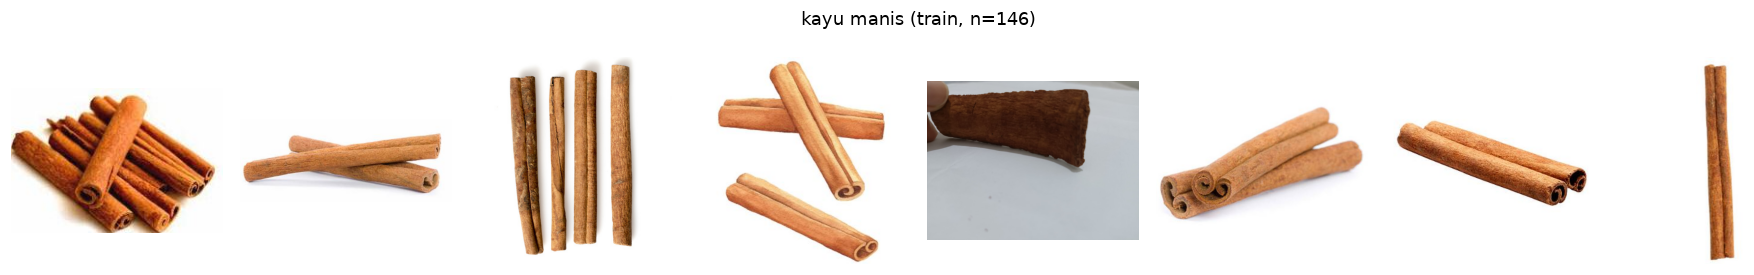

In [12]:
def show_class(label, n=8, split="train"):
    pool = meta[(meta["label"] == label) & (meta["split"] == split)]
    idx = rng.choice(len(pool), size=min(n, len(pool)), replace=False)
    fig, axes = plt.subplots(1, len(idx), figsize=(2.1 * len(idx), 2.5))
    axes = np.atleast_1d(axes)
    for ax, i in zip(axes, idx):
        row = pool.iloc[i]
        ax.imshow(Image.open(PROJECT_DIR / row.filepath).convert("RGB"))
        ax.axis("off")
    fig.suptitle(f"{label} ({split}, n={len(pool)})")
    plt.tight_layout()
    plt.show()


# Kelas kontrol negatif + kelas dengan citra terkecil & terbesar: paling rawan masalah
focus = ["bukan rempah", dist["total"].idxmin(), dist["total"].idxmax()]
for label in dict.fromkeys(l for l in focus if l in set(labels)):
    show_class(label)

        kasus      label split  width  height   aspect        kb                                       filepath
     terkecil   kapulaga train     86      92 0.934783  4.618164     data_split/train/kapulaga/kapulaga_116.jpg
     terkecil kayu manis   val    132      65 2.030769  3.957031    data_split/val/kayu manis/kayu-manis_62.JPG
     terkecil daun salam train     95      93 1.021505  4.479492  data_split/train/daun salam/daun-salam_96.JPG
     terkecil kayu manis train    112      82 1.365854  3.802734 data_split/train/kayu manis/kayu-manis_149.JPG
 paling lebar     jinten train    402     118 3.406780 16.165039          data_split/train/jinten/jinten_78.JPG
 paling lebar     jinten  test    365     139 2.625899  9.174805           data_split/test/jinten/jinten_61.JPG
 paling lebar   kapulaga train    612     237 2.582278 25.061523      data_split/train/kapulaga/kapulaga_53.JPG
 paling lebar       jahe train    351     138 2.543478 10.541016              data_split/train/jahe/jahe

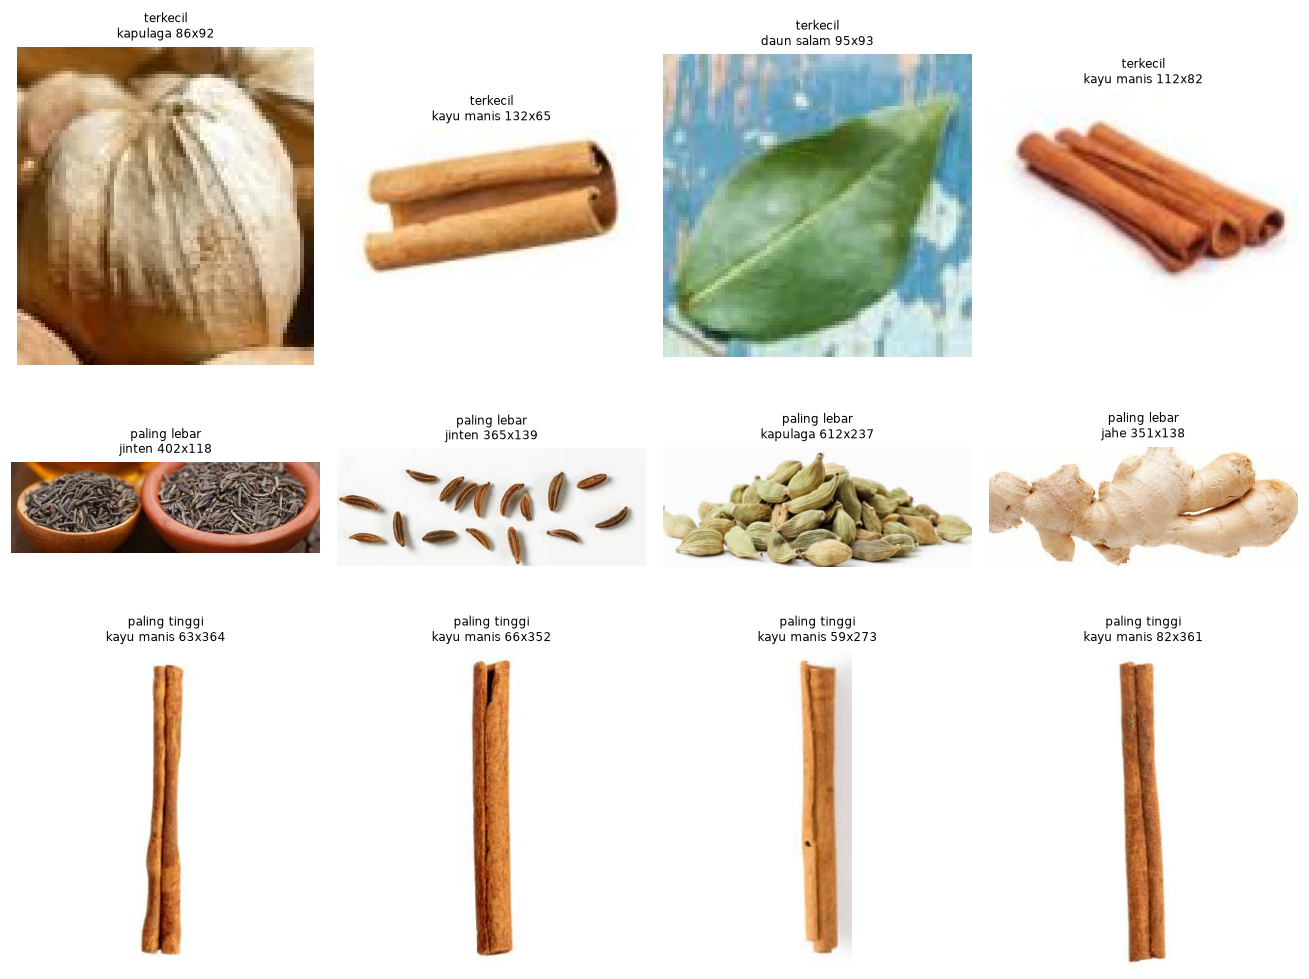

In [13]:
# Citra dengan dimensi/aspect ratio ekstrem -> kandidat gambar rusak, kolase, atau banner
extreme = pd.concat([
    meta.nsmallest(4, "megapixel").assign(kasus="terkecil"),
    meta.nlargest(4, "aspect").assign(kasus="paling lebar"),
    meta.nsmallest(4, "aspect").assign(kasus="paling tinggi"),
])
print(extreme[["kasus", "label", "split", "width", "height", "aspect", "kb", "filepath"]].to_string(index=False))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
for ax, row in zip(axes.ravel(), extreme.itertuples(index=False)):
    ax.imshow(Image.open(PROJECT_DIR / row.filepath).convert("RGB"))
    ax.set_title(f"{row.kasus}\n{row.label} {row.width}x{row.height}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Statistik Kanal RGB
Nilai mean/std per kanal dari **train saja** (val/test tidak boleh ikut memengaruhi preprocessing).
Dipakai untuk memutuskan: normalisasi dengan statistik dataset sendiri, atau statistik ImageNet
(yang biasanya lebih tepat saat memakai bobot pretrained).

statistik kanal:   0%|          | 0/1200 [00:00<?, ?it/s]

statistik kanal:   1%|          | 14/1200 [00:00<00:08, 138.26it/s]

statistik kanal:   3%|▎         | 38/1200 [00:00<00:05, 197.26it/s]

statistik kanal:   5%|▍         | 58/1200 [00:00<00:06, 165.03it/s]

statistik kanal:   8%|▊         | 100/1200 [00:00<00:04, 254.09it/s]

statistik kanal:  11%|█         | 127/1200 [00:00<00:04, 238.74it/s]

... (38 outputs left out)

statistik kanal:  97%|█████████▋| 1161/1200 [00:05<00:00, 331.39it/s]

statistik kanal: 100%|█████████▉| 1196/1200 [00:05<00:00, 327.60it/s]

statistik kanal: 100%|██████████| 1200/1200 [00:05<00:00, 217.12it/s]


Sampel: 1200 citra train
mean (R,G,B): [0.6394, 0.5817, 0.4941]
std  (R,G,B): [0.2824, 0.2917, 0.3253]

ImageNet reference:
mean: [0.485, 0.456, 0.406]
std : [0.229, 0.224, 0.225]


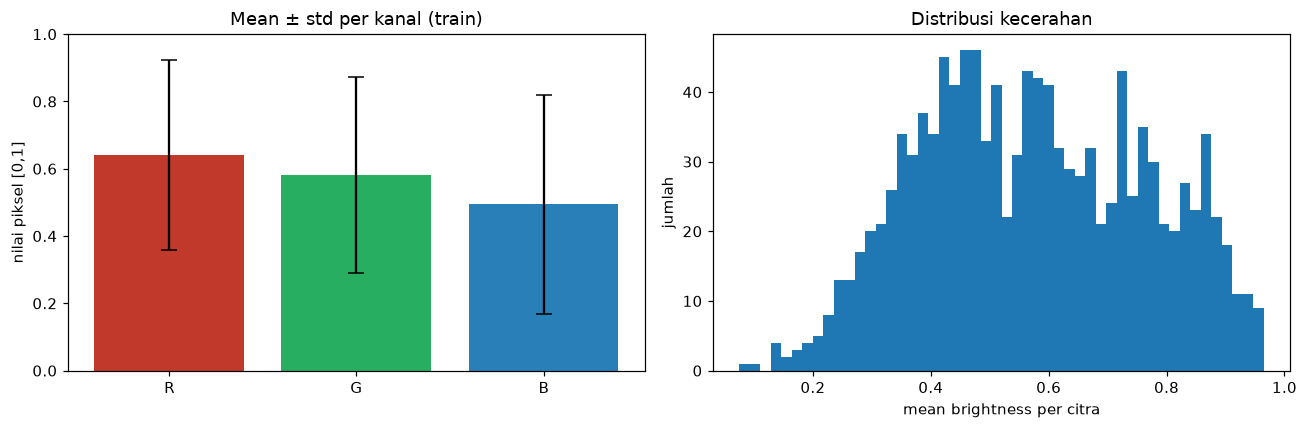


Citra sangat gelap (mean < 0.15): 7
Citra sangat terang (mean > 0.85): 112


In [14]:
SAMPLE_N = 1200   # cukup untuk estimasi stabil tanpa membaca seluruh train set
RESIZE_TO = 64

train_meta = meta[meta["split"] == "train"]
sample = train_meta.sample(min(SAMPLE_N, len(train_meta)), random_state=42)

sums = np.zeros(3)
sqs = np.zeros(3)
npix = 0
brightness = []

for row in tqdm(sample.itertuples(index=False), total=len(sample), desc="statistik kanal"):
    with Image.open(PROJECT_DIR / row.filepath) as im:
        a = np.asarray(im.convert("RGB").resize((RESIZE_TO, RESIZE_TO), Image.BILINEAR), dtype=np.float64) / 255.0
    sums += a.sum(axis=(0, 1))
    sqs += (a ** 2).sum(axis=(0, 1))
    npix += a.shape[0] * a.shape[1]
    brightness.append(a.mean())

mean = sums / npix
std = np.sqrt(sqs / npix - mean ** 2)

print(f"\nSampel: {len(sample)} citra train")
print("mean (R,G,B):", np.round(mean, 4).tolist())
print("std  (R,G,B):", np.round(std, 4).tolist())
print("\nImageNet reference:")
print("mean: [0.485, 0.456, 0.406]")
print("std : [0.229, 0.224, 0.225]")

brightness = np.asarray(brightness)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(["R", "G", "B"], mean, yerr=std, capsize=5, color=["#c0392b", "#27ae60", "#2980b9"])
axes[0].set(ylim=(0, 1), ylabel="nilai piksel [0,1]", title="Mean ± std per kanal (train)")
axes[1].hist(brightness, bins=50)
axes[1].set(xlabel="mean brightness per citra", ylabel="jumlah", title="Distribusi kecerahan")
plt.tight_layout()
plt.show()

print(f"\nCitra sangat gelap (mean < 0.15): {(brightness < 0.15).sum()}")
print(f"Citra sangat terang (mean > 0.85): {(brightness > 0.85).sum()}")

## 7. Smoke Test `ImageFolder`
Pemeriksaan terakhir: pastikan pipeline torchvision benar-benar bisa membaca data ini,
dan urutan `class_to_idx` konsisten di ketiga split (kalau berbeda, label jadi tertukar saat evaluasi).

In [15]:
import torch
from torchvision import datasets, transforms

tf = transforms.Compose([transforms.Resize((224, 224)), transforms.ToTensor()])
ds = {s: datasets.ImageFolder(SPLIT_DIR / s, transform=tf) for s in SPLITS}

for s in SPLITS:
    print(f"{s:5s}: {len(ds[s]):5d} citra, {len(ds[s].classes)} kelas")

assert ds["train"].class_to_idx == ds["val"].class_to_idx == ds["test"].class_to_idx, \
    "Mapping kelas berbeda antar split!"
print("\nMapping kelas konsisten di train/val/test.")

loader = torch.utils.data.DataLoader(ds["train"], batch_size=16, shuffle=True, num_workers=0)
x, y = next(iter(loader))
print(f"\nBatch shape : {tuple(x.shape)}  dtype={x.dtype}")
print(f"Rentang nilai: [{x.min():.3f}, {x.max():.3f}]")
print(f"Label batch  : {y.tolist()}")
print("NaN/Inf      :", bool(torch.isnan(x).any() or torch.isinf(x).any()))

train:  4221 citra, 31 kelas
val  :   905 citra, 31 kelas
test :   905 citra, 31 kelas

Mapping kelas konsisten di train/val/test.

Batch shape : (16, 3, 224, 224)  dtype=torch.float32
Rentang nilai: [0.000, 1.000]
Label batch  : [20, 17, 1, 4, 2, 3, 25, 14, 11, 11, 14, 10, 18, 25, 17, 2]
NaN/Inf      : False


## 8. Ringkasan Sanity Check

In [16]:
checks = [
    ("Manifest konsisten dengan disk", len(missing_on_disk) == 0 and len(untracked) == 0,
     f"{len(missing_on_disk)} hilang, {len(untracked)} tak tercatat"),
    ("Tidak ada file non-gambar di folder split", len(stray) == 0, f"{len(stray)} file"),
    ("Semua citra bisa didecode", len(broken_df) == 0, f"{len(broken_df)} gagal dibaca"),
    (">= 5 kelas", manifest["label"].nunique() >= 5, f"{manifest['label'].nunique()} kelas"),
    (">= 1000 citra", len(meta) >= 1000, f"{len(meta)} citra"),
    ("Imbalance ratio < 3x", dist["total"].max() / dist["total"].min() < 3,
     f"{dist['total'].max() / dist['total'].min():.2f}x"),
    ("Stratifikasi split terjaga (dev < 2%)", (prop["train"] - 0.70).abs().max() < 0.02,
     f"deviasi maks {(prop['train'] - 0.70).abs().max():.4f}"),
    ("Tidak ada duplikat byte-identik", len(dup_md5) == 0, f"{len(dup_md5)} file"),
    ("Tidak ada near-duplicate terverifikasi", len(dup_ph) == 0, f"{len(dup_ph)} file"),
    ("Tidak ada kebocoran antar split", len(leak_md5) == 0 and len(leak_ph) == 0,
     f"md5: {len(leak_md5)} grup, dhash: {len(leak_ph)} grup"),
    ("Tidak ada label konflik pada gambar identik", len(conflict_md5) == 0 and len(conflict_ph) == 0,
     f"{len(conflict_md5) + len(conflict_ph)} grup"),
    ("Semua citra >= 224 px di kedua sisi", len(too_small) == 0,
     f"{len(too_small)} citra ({len(too_small)/len(meta):.1%}) lebih kecil"),
    ("Semua citra mode RGB", len(non_rgb) == 0, f"{len(non_rgb)} non-RGB"),
    ("ImageFolder terbaca & mapping konsisten", True,
     f"{sum(len(d) for d in ds.values())} citra terbaca"),
]

report = pd.DataFrame(
    [{"pemeriksaan": n, "status": "PASS" if ok else "PERHATIAN", "detail": d} for n, ok, d in checks]
)
print(report.to_string(index=False))

n_warn = (report["status"] == "PERHATIAN").sum()
print(f"\n{len(report) - n_warn}/{len(report)} pemeriksaan PASS, {n_warn} perlu perhatian.")

                                pemeriksaan    status                        detail
             Manifest konsisten dengan disk      PASS      0 hilang, 0 tak tercatat
  Tidak ada file non-gambar di folder split      PASS                        0 file
                  Semua citra bisa didecode      PASS                0 gagal dibaca
                                 >= 5 kelas      PASS                      31 kelas
                              >= 1000 citra      PASS                    6031 citra
                       Imbalance ratio < 3x      PASS                         1.73x
      Stratifikasi split terjaga (dev < 2%)      PASS           deviasi maks 0.0032
            Tidak ada duplikat byte-identik      PASS                        0 file
     Tidak ada near-duplicate terverifikasi      PASS                        0 file
            Tidak ada kebocoran antar split      PASS    md5: 0 grup, dhash: 0 grup
Tidak ada label konflik pada gambar identik      PASS                       